# ДЗ по single cell номер 2: Аннотация scRNA-seq хряща (GSE255460) + анализ сигналинга 15-PGDH ($HPGD$) / $PGE_2$–EP4 при остеоартрите

**Цель работы:**
Провести полный пайплайн на реальном датасете суставного хряща человека **GSE255460**.


### А причём тут остеоартрит?

Моя тема диплома - Дизайн селективных ингибиторов к 15-PGDH для лечения остеоартрита.

 Этот фермент превращает **$PGE_2$** в **$15-oxoprostaglandinE_2$** и тем самым нарушает каскад где $PGE_2$ через рецептор `PTGER4` активирует  `cAMP -> PKA (PRKACA) -> CREB1 -> SOX9`, а `SOX9` как транскрипционный фактор стимулирует синтез внеклеточного матрикса (`COL2A1`, `ACAN`), тем самым запуская регенерацию - то что нужно при хроническом ОА. И по идее это всё идёт при **умеренном уровне воспаления**

В то же время, в литературе есть и второй каскад. **При высоком уровне цитокинового шторма (`IL1B`, `TNF`, `IL6`):** гиперактивация `PTGER4` смещает сигналинг в сторону `STAT3`-зависимой транскрипции металлопротеиназ и аггреканаз (`MMP3`, `MMP13`, `ADAMTS4`, `ADAMTS5`), запуская порочный круг разрушения матрикса, где для разрыва петли **необходима активность 15-PGDH** и предварительное подавление воспаления.

Ну то есть всё как обычно, может получиться ситуация из серии одно лечим другое калечим. И хотя чуваки из стенфорда DOI: 10.1126/science.adx6649 показали что вроде бы второй путь не активируется и хондроциты должны **ПЕРЕПРОГРАММИРОВАТЬСЯ** в регенеративные, но всегда интресно, а как это всё дело представлено в **single cell данных?)**

### МОИ цели:

1. Разобраться как меняется кластеризация хондроцитов в зависимости от того, есть ОА или НЕТ?
2. Рассмотреть, как экспрессия генов каждого из путей связанных с рецетором E4 и 15-PGDH в частности, отличается у больных и здоровых?
3. Посмотреть, есть ли корреляция между типом клеток, избранным путём сигналинга E4 и уровнем воспаления?
4. Сделать вывод, могут ли single cell данные подтвердить мой литобзор?)

## 0. Подготовка окружения и сборка GSE255460




## 3 контроля + 3 OA-пациента (оба среза NWB/WB(части хряща без нагрузки и с ней)).

In [1]:
from pathlib import Path
import warnings
import tarfile
import gzip
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
from scipy.stats import mannwhitneyu

warnings.filterwarnings("ignore")
np.random.seed(42)
sc.settings.verbosity = 1
sc.set_figure_params(figsize=(12, 6), dpi=100, frameon=False)

DATA_DIR = Path("data_gse255460")
RAW_TAR_PATH = DATA_DIR / "GSE255460_RAW.tar"
META_PATH = DATA_DIR / "GSE255460_metadata.csv.gz"
SAMPLES_DIR = DATA_DIR / "samples"

# Какие образцы грузим: 3 контроля + 3 OA-пациента (оба среза NWB/WB).
# Список можно расширить, например: OA_IDS = ["OA1-1", ..., "OA8-2"].
CONTROL_IDS = ["C1", "C2", "C3"]
OA_IDS = ["OA1-1", "OA1-2", "OA2-1", "OA2-2", "OA4-1", "OA4-2"]
SELECTED_IDS = CONTROL_IDS + OA_IDS

print("RAW tar:", RAW_TAR_PATH.exists(), "| metadata:", META_PATH.exists())
print(f"Выбрано образцов: {len(SELECTED_IDS)} -> {SELECTED_IDS}")


RAW tar: True | metadata: True
Выбрано образцов: 9 -> ['C1', 'C2', 'C3', 'OA1-1', 'OA1-2', 'OA2-1', 'OA2-2', 'OA4-1', 'OA4-2']


### 0.1. Сборка объекта: сопоставление образцов по баркодам и конкатенация

Метаданные содержат баркоды с префиксом (`S1WK.AAAC...-1`), а в 10x-матрицах баркод хранится без префикса (`AAAC...-1`). Кроме того, **имена GSM в tar-архиве для OA3–OA8 сдвинуты относительно метаданных**. Поэтому соответствие «файл → пациент» определяется не по имени файла, а по максимальному пересечению баркодов с метаданными.


In [2]:
# ---------------------------------------------------------------------------
# 1. Метаданные GEO
# ---------------------------------------------------------------------------
meta_df = pd.read_csv(META_PATH, index_col=0)
meta_df.index.name = "cell_barcode"
meta_df["barcode"] = meta_df.index.str.rsplit(".", n=1).str[-1]

assert {"ID", "trait", "group", "sample", "celltype"}.issubset(meta_df.columns)

# ---------------------------------------------------------------------------
# 2. Читаем только баркоды из tar и определяем истинные ID образцов
# ---------------------------------------------------------------------------
def read_barcodes_from_tar(tar):
    out = {}
    for member in tar.getmembers():
        if member.name.endswith("_barcodes.tsv.gz"):
            with tar.extractfile(member) as fh:
                out[member.name] = gzip.decompress(fh.read()).decode().splitlines()
    return out


with tarfile.open(RAW_TAR_PATH, "r") as tar:
    tar_barcodes = read_barcodes_from_tar(tar)
    id_to_bc = meta_df.groupby("ID")["barcode"].apply(set).to_dict()

    gsm_prefix_to_id = {}
    for name, barcodes in tar_barcodes.items():
        prefix = name[: -len("_barcodes.tsv.gz")]
        bset = set(barcodes)
        overlaps = {idv: len(bset & mset) for idv, mset in id_to_bc.items()}
        best_id = max(overlaps, key=overlaps.get)
        best_ov = overlaps[best_id]
        denom = max(1, min(len(bset), len(id_to_bc[best_id])))
        gsm_prefix_to_id[prefix] = (best_id, best_ov, best_ov / denom)

    id_to_prefix = {}
    for prefix, (idv, ov, frac) in gsm_prefix_to_id.items():
        if idv in SELECTED_IDS and frac > 0.9:
            id_to_prefix.setdefault(idv, []).append((prefix, ov, frac))

    missing = [i for i in SELECTED_IDS if i not in id_to_prefix]
    assert not missing, f"Не найдены файлы для образцов: {missing}"

    # если на один ID нашлось несколько файлов — берём с максимальным пересечением
    id_to_prefix = {k: sorted(v, key=lambda x: -x[1])[0][0] for k, v in id_to_prefix.items()}

    # -----------------------------------------------------------------------
    # 3. Распаковываем только выбранные образцы
    # -----------------------------------------------------------------------
    SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
    suffixes = {
        "_matrix.mtx.gz": "matrix.mtx.gz",
        "_barcodes.tsv.gz": "barcodes.tsv.gz",
        "_features.tsv.gz": "features.tsv.gz",
    }
    for idv, prefix in id_to_prefix.items():
        out_dir = SAMPLES_DIR / idv
        out_dir.mkdir(parents=True, exist_ok=True)
        for member in tar.getmembers():
            for suffix, new_name in suffixes.items():
                if member.name == prefix + suffix:
                    (out_dir / new_name).write_bytes(tar.extractfile(member).read())

# ---------------------------------------------------------------------------
# 4. Чтение и аннотация каждого образца по метаданным
# ---------------------------------------------------------------------------
adatas = {}
for idv in SELECTED_IDS:
    a = sc.read_10x_mtx(
        SAMPLES_DIR / idv,
        var_names="gene_symbols",
        make_unique=True,
        cache=False,
    )
    a.var_names_make_unique()

    sub = meta_df[meta_df["ID"] == idv]
    bc_to_idx = dict(zip(sub["barcode"], sub.index))
    meta_idx = [bc_to_idx.get(bc) for bc in a.obs_names]
    mask = np.array([x is not None for x in meta_idx])
    a = a[mask].copy()
    meta_idx = [x for x in meta_idx if x is not None]
    sub = meta_df.loc[meta_idx]

    a.obs_names = [f"{idv}_{bc}" for bc in a.obs_names]
    a.obs["sample_id"] = idv
    a.obs["patient"] = sub["sample"].astype(str).values
    a.obs["condition"] = sub["trait"].astype(str).values
    a.obs["group"] = sub["group"].astype(str).values
    a.obs["author_celltype"] = sub["celltype"].astype(str).values
    a.obs["gsm_sample"] = id_to_prefix[idv]
    adatas[idv] = a

    print(
        f"{idv:7s} <- {id_to_prefix[idv]:18s} | клеток: {a.n_obs:6d} | "
        f"condition: {a.obs['condition'].unique().tolist()}"
    )

# ---------------------------------------------------------------------------
# 5. Конкатенация образцов
# ---------------------------------------------------------------------------
adata = ad.concat(
    list(adatas.values()),
    label="sample_key",
    keys=list(adatas.keys()),
    index_unique=None,
    join="outer",
    fill_value=0,
)
adata.var_names_make_unique()
del adatas

adata.obs["condition"] = adata.obs["condition"].astype("category")
adata.obs["group"] = adata.obs["group"].astype("category")
adata.obs["sample_id"] = adata.obs["sample_id"].astype("category")
adata.obs["patient"] = adata.obs["patient"].astype("category")
adata.obs["author_celltype"] = adata.obs["author_celltype"].astype("category")
adata.layers["counts"] = adata.X.copy()

print(adata)
print("\nКлетки по когортам:")
print(adata.obs["condition"].value_counts())
print("\nКлетки по группам (NWB/WB/Control):")
print(adata.obs["group"].value_counts())
print("\nКросс-таблица образец × когорта:")
display(pd.crosstab(adata.obs["sample_id"], adata.obs["condition"]))


C1      <- GSM8072834_C1      | клеток:   1345 | condition: ['Control']
C2      <- GSM8072835_C2      | клеток:   8183 | condition: ['Control']
C3      <- GSM8072836_C3      | клеток:   6979 | condition: ['Control']
OA1-1   <- GSM8072837_OA1-1   | клеток:  11731 | condition: ['OA']
OA1-2   <- GSM8072838_OA1-2   | клеток:   8994 | condition: ['OA']
OA2-1   <- GSM8072839_OA2-1   | клеток:   5263 | condition: ['OA']
OA2-2   <- GSM8072840_OA2-2   | клеток:  10457 | condition: ['OA']
OA4-1   <- GSM8072847_OA6-1   | клеток:   9807 | condition: ['OA']
OA4-2   <- GSM8072848_OA6-2   | клеток:  12006 | condition: ['OA']
AnnData object with n_obs × n_vars = 74765 × 61134
    obs: 'sample_id', 'patient', 'condition', 'group', 'author_celltype', 'gsm_sample', 'sample_key'
    layers: 'counts'

Клетки по когортам:
condition
OA         58258
Control    16507
Name: count, dtype: int64

Клетки по группам (NWB/WB/Control):
group
WB         31457
NWB        26801
Control    16507
Name: count, dtype: int6

condition,Control,OA
sample_id,,
C1,1345,0
C2,8183,0
C3,6979,0
OA1-1,0,11731
OA1-2,0,8994
OA2-1,0,5263
OA2-2,0,10457
OA4-1,0,9807
OA4-2,0,12006


### 0.2. QC, нормализация, HVG, Combat и кластеризация

Мультисэмпловый объект обрабатывается целиком: QC → `normalize_total` + `log1p` → HVG с учётом `sample_id` → `sc.pp.combat` (на HVG-подмножестве, чтобы не гонять 36k генов × десятки тысяч клеток) → PCA/UMAP/Leiden. Combat применяется только для построения пространства PCA; маркерные плоты идут по исходной лог-нормализации.


In [3]:
# ---------------------------------------------------------------------------
# 1. QC
# ---------------------------------------------------------------------------
if "counts" not in adata.layers:
    adata.layers["counts"] = adata.X.copy()

adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains(r"^HB[^(P)]", regex=True)
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], percent_top=None, log1p=True, inplace=True
)

print(f"Клеток до фильтрации: {adata.n_obs}, генов: {adata.n_vars}")
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["pct_counts_mt"] < 15) & (adata.obs["n_genes_by_counts"] < 6000)
].copy()
print(f"Клеток после фильтрации: {adata.n_obs}, генов: {adata.n_vars}")
print(adata.obs["condition"].value_counts())

# ---------------------------------------------------------------------------
# 2. Нормализация
# ---------------------------------------------------------------------------
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# ---------------------------------------------------------------------------
# 3. HVG с учётом образца
# ---------------------------------------------------------------------------
sc.pp.highly_variable_genes(
    adata, n_top_genes=2000, flavor="seurat", batch_key="sample_id"
)

# ---------------------------------------------------------------------------
# 4. Combat на HVG -> PCA (скорректированное пространство для UMAP/Leiden)
# ---------------------------------------------------------------------------
adata_hvg = adata[:, adata.var["highly_variable"].values].copy()
sc.pp.combat(adata_hvg, key="sample_id")
sc.tl.pca(adata_hvg, n_comps=50, random_state=42)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
adata.uns["pca"] = adata_hvg.uns["pca"]
del adata_hvg

# ---------------------------------------------------------------------------
# 5. Граф соседства, UMAP, Leiden
# ---------------------------------------------------------------------------
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca", random_state=42)
sc.tl.umap(adata, min_dist=0.3, random_state=42)

for res in (0.2, 0.6, 1.0):
    key = f"leiden_{res:.1f}"
    sc.tl.leiden(adata, resolution=res, key_added=key, random_state=42)

print("Кластеризация завершена:", [c for c in adata.obs.columns if c.startswith("leiden_")])


Клеток до фильтрации: 74765, генов: 61134
Клеток после фильтрации: 74375, генов: 34478
condition
OA         58258
Control    16117
Name: count, dtype: int64
Кластеризация завершена: ['leiden_0.2', 'leiden_0.6', 'leiden_1.0']


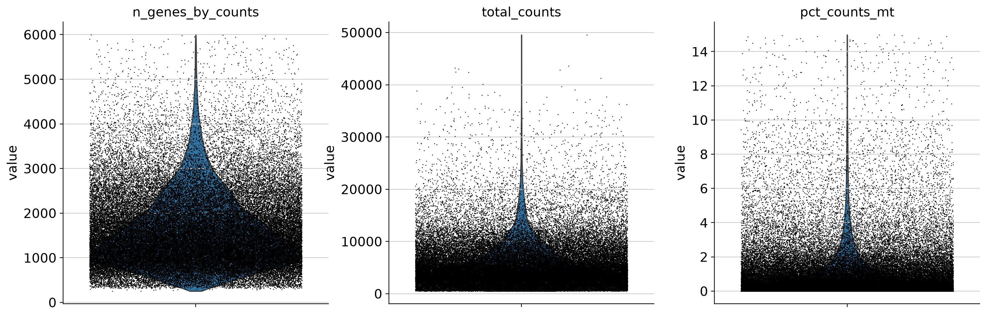

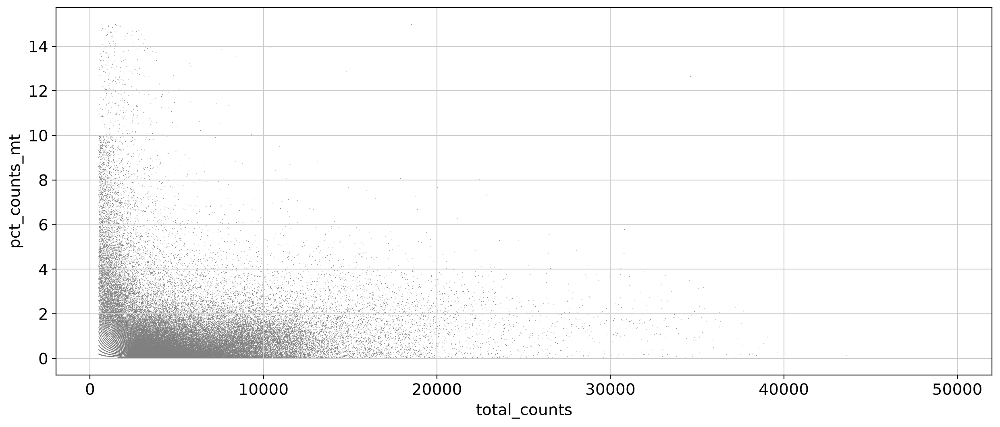

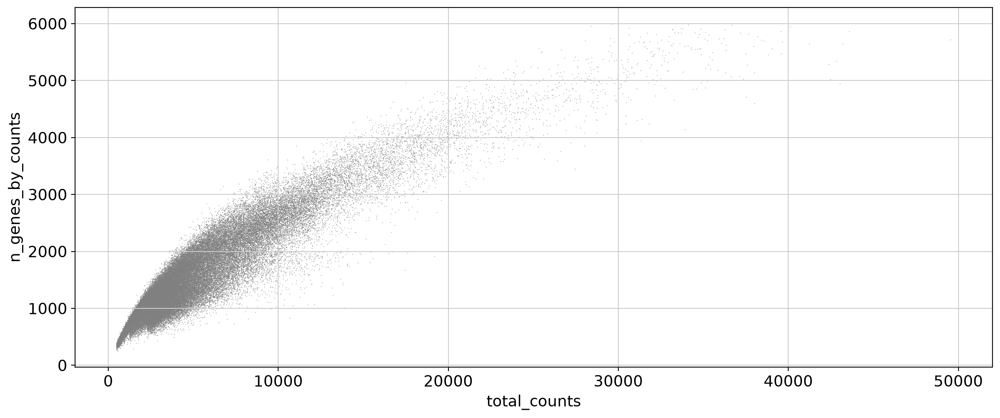

In [61]:
# Задание 1: Графики QC
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

**Обоснование порогов QC:**
*   `min_genes=200`: Исключаем пустые капли
*   `n_genes_by_counts < 6000`: Исключаем клетки с аномально высоким числом детектированных генов.
*   `pct_counts_mt < 15`: Исключаем мертвые или умирающие клетки

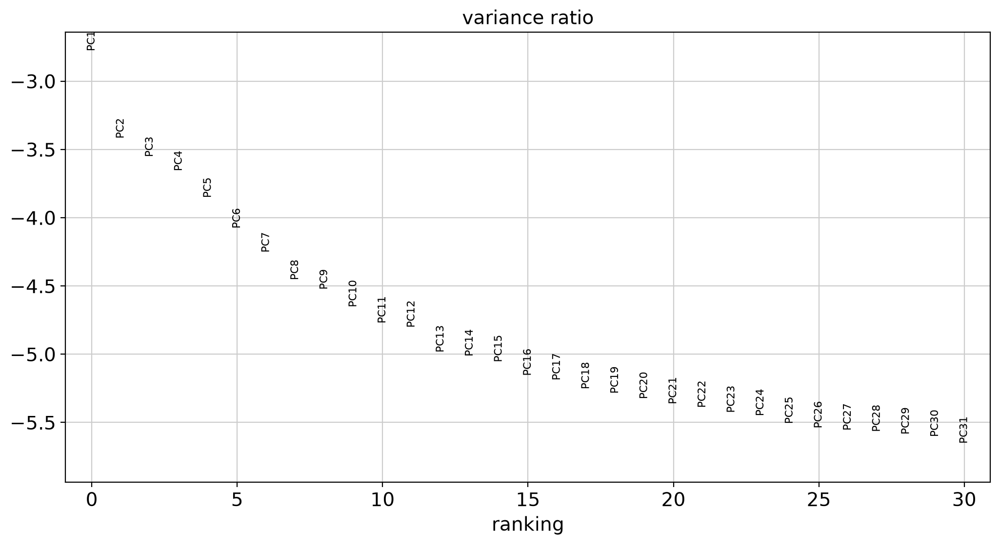

In [64]:
# Задание 3: График объясненной дисперсии
sc.pl.pca_variance_ratio(adata, log=True)

    **Сравнение кластеров (Leiden):**
*   Увеличение `resolution` ведет к дроблению крупных кластеров на более мелкие (число кластеров растет с 6 при res=0.2 до 21 при res=1.0).
*   Каждый получившийся кластер **не обязательно** соответствует отдельному типу клеток. Часто это могут быть промежуточные состояния (градиент дифференцировки) или технические артефакты (например, разные фазы клеточного цикла).

## 1. Обзор кластеризации и поиск маркерных генов


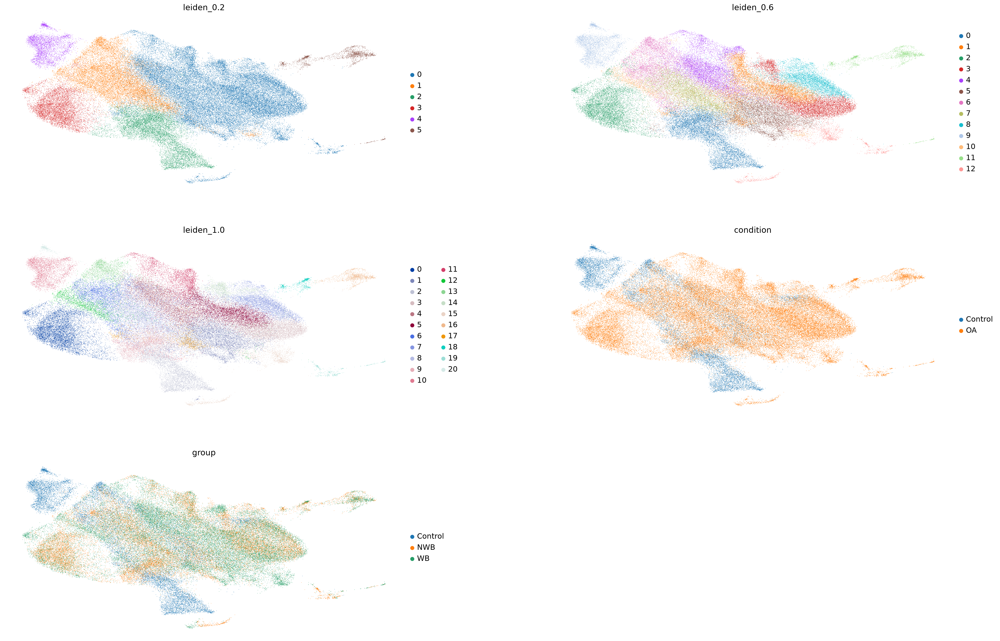

In [4]:
CLUSTER_KEY = "leiden_0.6"

sc.pl.umap(
    adata,
    color=["leiden_0.2", "leiden_0.6", "leiden_1.0", "condition", "group"],
    ncols=2,
    use_raw=False,
    wspace=0.25,
)


### **Вывод:** Можно заметить, что группы клеток из контроля и из больных не сильно перекрываются. Остеоартрит меняет экспрессию в клетках достаточно сильно.

### Также, можно заметить, что впринципе не важно откуда взят образец, из WB - те части на которых большая нагрузка и NWB - части с небольшой нагрузкой. По-сути не меняется особо ничего.
 Дальше возьмём leiden 0.6 за основу.

### 1.1. Поиск дифференциально экспрессируемых генов (`rank_genes_groups`) по кластерам


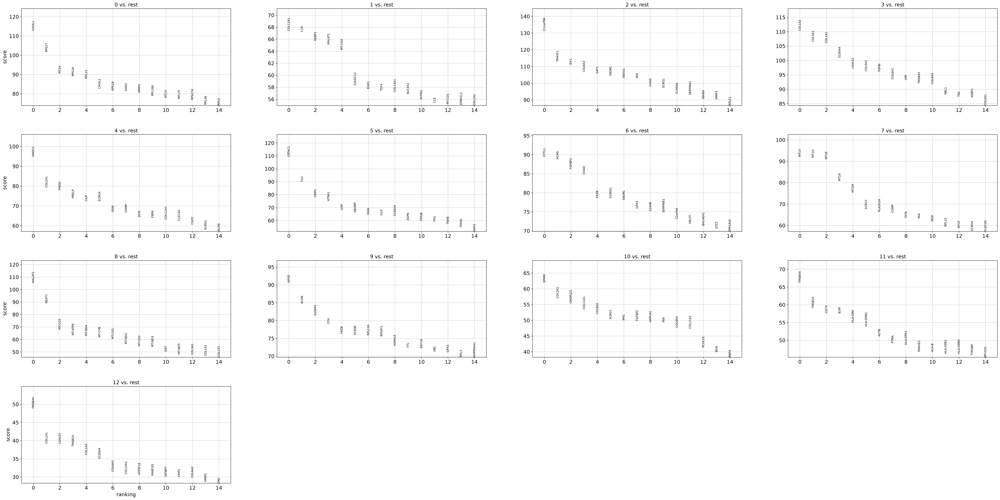

In [5]:
sc.tl.rank_genes_groups(
    adata,
    groupby=CLUSTER_KEY,
    method="wilcoxon",
    corr_method="benjamini-hochberg",
    pts=True,
    use_raw=False,
    key_added="rank_genes_leiden"
)

sc.pl.rank_genes_groups(
    adata,
    n_genes=15,
    sharey=False,
    key="rank_genes_leiden"
)


In [ ]:
# Выводим топ-1 
markers_df = sc.get.rank_genes_groups_df(adata, group=None, key="rank_genes_leiden")
top_markers = (
    markers_df.query("pvals_adj < 0.05 and logfoldchanges > 0.5")
    .groupby("group", observed=False)
    .head(1)
)
display(top_markers[["group", "names", "logfoldchanges", "pvals_adj", "pct_nz_group"]])


,group,names,logfoldchanges,pvals_adj,pct_nz_group
0,0,CHI3L1,3.908724,0.0,0.955766
34478,1,COL12A1,2.182230,0.0,0.726793
68956,2,C11orf96,7.356649,0.0,0.966329
103434,3,COL1A2,4.671572,0.0,0.980052
137912,4,SMOC2,2.777511,0.0,0.903994
172390,5,CRTAC1,3.575326,0.0,0.938615
206868,6,CYTL1,4.393239,0.0,0.900046
241346,7,MT1X,3.002064,0.0,0.997084
275824,8,MALAT1,2.480265,0.0,0.998065
310302,9,APOD,5.284399,0.0,0.988256


### Я хочу найти дегенеративные клетки хряща, поэтому интерсно что делают кластеры 11 и 12 TMSB4X (Thymosin Beta 4, X-linked) В хондроцитах высокий уровень TMSB4X маркирует субпопуляцию с высокой пластичностью (хондрогенные клетки-предшественники / CPCs или активированные репаративные клетки) - по сути почти стволовые, тоже может быть интересно, ведь в классической аннотации их нет.

## 2. Аннотация субпопуляций хондроцитов (по каноническим маркерам GSE255460, *Fan et al.*)

В суставном хряще человека выделяют основные функциональные состояния хондроцитов:
* **HomC (Гомеостатические хондроциты):** поддерживают здоровый внеклеточный матрикс (`COL2A1`, `SOX9`, `ACAN`, `COMP`, `MMP2`).
* **RegC (Регуляторные / Репаративные хондроциты):** отвечают за адаптивный ответ и раннюю регенерацию (`CHI3L1`, `CHI3L2`, `CRTAC1`, `CLU`).
* **PreHTC / HTC (Прегипертрофические и гипертрофические):** терминальная дифференцировка и кальцификация матрикса (`COL10A1`, `IBSP`, `TGFBI`, `RUNX2`, `VEGFA`).
* **FC (Фиброхондроциты):** замещение гиалинового хряща фиброзным коллагеном I/III типа (`COL1A1`, `COL1A2`, `COL3A1`, `PRG4`, `TMSB4X`).
* **InfC (Воспалительные хондроциты):** продуцируют цитокины, хемокины и матриксные металлопротеиназы (`IL1B`, `TNF`, `IL6`, `CCL2`, `CXCL8`, `MMP3`, `MMP13`, `NFKBIA`).


  HomC (Homeostatic): ['COL2A1', 'SOX9', 'ACAN', 'COMP', 'MATN3', 'FRZB']
  RegC (Regulatory): ['CHI3L1', 'CHI3L2', 'CRTAC1', 'CLU', 'APOD']
  PreHTC/HTC (Hypertrophic): ['TGFBI', 'COL10A1', 'IBSP', 'RUNX2', 'SPP1', 'VEGFA']
  FC (Fibrocartilage): ['COL1A1', 'COL1A2', 'COL3A1', 'THY1', 'PRG4', 'FN1']
  InfC (Inflammatory): ['IL1B', 'TNF', 'IL6', 'CCL2', 'CXCL8', 'NFKBIA', 'MMP3', 'MMP13']


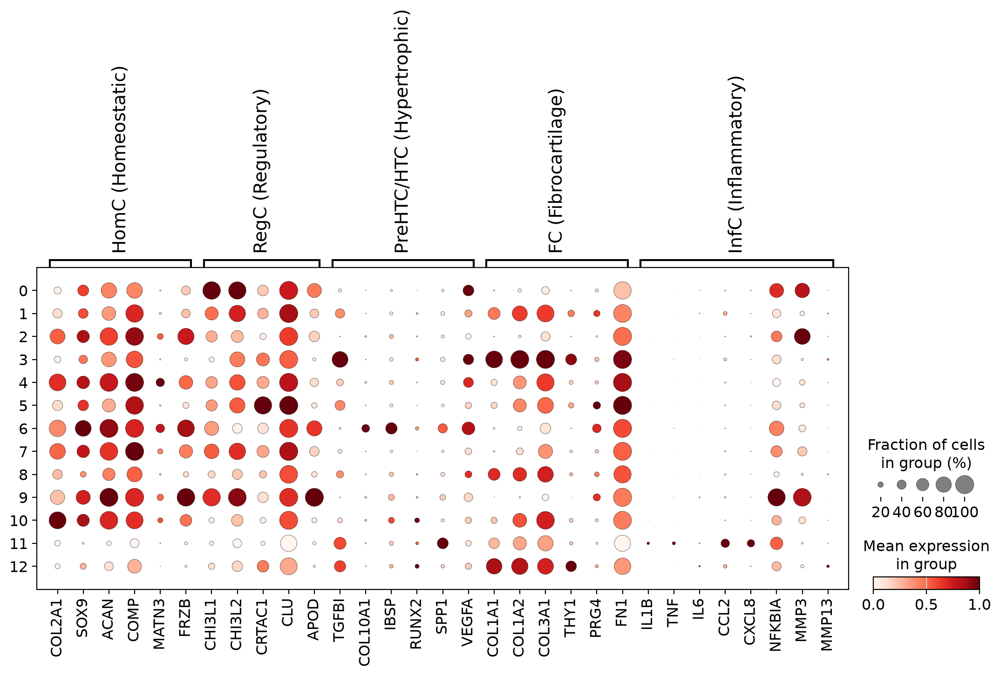

In [29]:
chondrocyte_markers = {
    "HomC (Homeostatic)": ["COL2A1", "SOX9", "ACAN", "COMP", "MATN3", "FRZB"],
    "RegC (Regulatory)": ["CHI3L1", "CHI3L2", "CRTAC1", "CLU", "APOD"],
    "PreHTC/HTC (Hypertrophic)": ["TGFBI", "COL10A1", "IBSP", "RUNX2", "SPP1", "VEGFA"],
    "FC (Fibrocartilage)": ["COL1A1", "COL1A2", "COL3A1", "THY1", "PRG4", "FN1"],
    "InfC (Inflammatory)": ["IL1B", "TNF", "IL6", "CCL2", "CXCL8", "NFKBIA", "MMP3", "MMP13"]
}

# Оставляем только те гены, которые присутствуют в матрице adata.var_names
chondrocyte_markers_present = {
    k: [g for g in v if g in adata.var_names]
    for k, v in chondrocyte_markers.items()
}
chondrocyte_markers_present = {k: v for k, v in chondrocyte_markers_present.items() if len(v) > 0}


for k, v in chondrocyte_markers_present.items():
    print(f"  {k}: {v}")

sc.pl.dotplot(
    adata,
    var_names=chondrocyte_markers_present,
    groupby=CLUSTER_KEY,
    use_raw=False,
    standard_scale="var",
)


### Вывод: В нашей выборке почти нет Inflammatory  и Hypertrofic - видимо их слишком мало. С 11 и 12 кластером. Их конечно закинет в FC, но SPP1 — канонический маркер  гипертрофических хондроцитов и он у них хорошо экспрессируется. Так что возможно они и есть эти околостволовые хондроциты.

### 2.1. Скоринг генных сигнатур (`sc.tl.score_genes`) и автоматическое присвоение меток кластерам


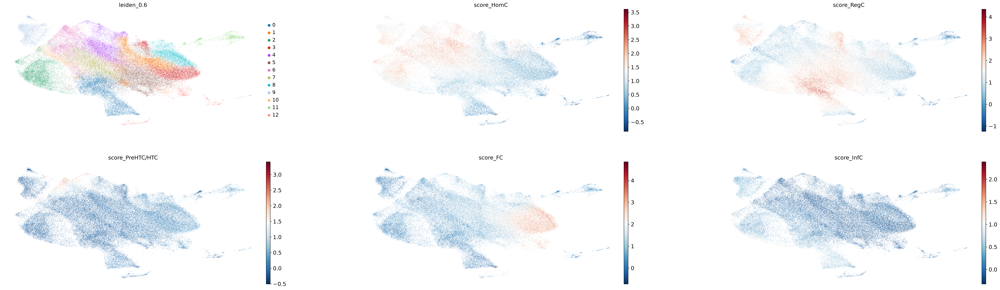

In [8]:
score_cols = []
for pop_name, gene_list in chondrocyte_markers_present.items():
    col_name = f"score_{pop_name.split()[0]}"
    sc.tl.score_genes(
        adata,
        gene_list=gene_list,
        score_name=col_name,
        use_raw=False,
        random_state=42
    )
    score_cols.append(col_name)

sc.pl.umap(
    adata,
    color=[CLUSTER_KEY] + score_cols,
    ncols=3,
    use_raw=False,
    cmap="RdBu_r",
    wspace=0.25
)


### Тут уже кластеризовали и понятно что у нас по сути только три больших группы

,score_HomC,score_RegC,score_PreHTC/HTC,score_FC,score_InfC
leiden_0.6,,,,,
0,0.503033,2.080265,-0.072237,0.174157,0.357794
1,0.672270,1.526617,-0.015704,1.423813,-0.049230
2,1.545359,0.767992,-0.059936,0.208892,0.399902
3,0.339683,0.648583,0.237248,2.419813,-0.094980
4,1.659933,1.151856,-0.004306,1.018744,-0.084334
5,0.655927,1.671345,-0.045874,1.217237,-0.067468
6,1.496467,0.945121,0.343864,0.223687,-0.051290
7,1.463034,1.473118,-0.124708,0.543414,0.047576
8,0.807340,1.014973,0.169060,1.850787,-0.046297


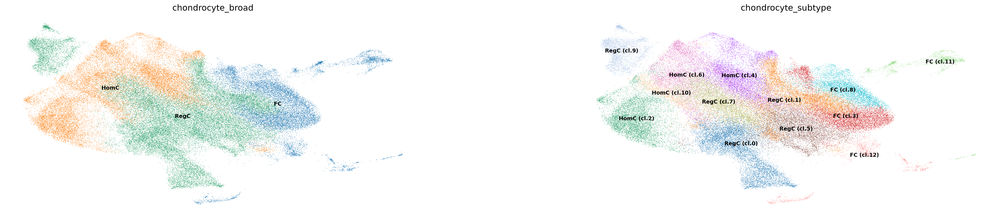

In [9]:
# Автоматически сопоставляем каждый кластер Leiden с субпопуляцией, имеющей максимальный средний скор
cluster_scores = adata.obs.groupby(CLUSTER_KEY, observed=False)[score_cols].mean()
display(cluster_scores.style.background_gradient(cmap="coolwarm", axis=1))

best_pop_per_cluster = cluster_scores.idxmax(axis=1).str.replace("score_", "")
cluster_to_celltype = {
    cl: f"{pop} (cl.{cl})" for cl, pop in best_pop_per_cluster.items()
}
cluster_to_broad_type = best_pop_per_cluster.to_dict()

adata.obs["chondrocyte_subtype"] = adata.obs[CLUSTER_KEY].map(cluster_to_celltype).astype("category")
adata.obs["chondrocyte_broad"] = adata.obs[CLUSTER_KEY].map(cluster_to_broad_type).astype("category")

sc.pl.umap(
    adata,
    color=["chondrocyte_broad", "chondrocyte_subtype"],
    legend_loc="on data",
    legend_fontsize=9,
    use_raw=False,
    wspace=0.25
)


### Итого, по скорам разделили основные три группы на субпопуляции.

### 2.2. Сравнение когорт: OA vs Control, NWB/WB и доли субпопуляций


Клетки по когортам (condition):
condition
OA         58258
Control    16117
Name: count, dtype: int64

Клетки по образцам (sample_id):
sample_id
OA4-2    12006
OA1-1    11731
OA2-2    10457
OA4-1     9807
OA1-2     8994
C2        8183
C3        6592
OA2-1     5263
C1        1342
Name: count, dtype: int64

Кросс-таблица образец × когорта:


condition,Control,OA
sample_id,,
C1,1342,0
C2,8183,0
C3,6592,0
OA1-1,0,11731
OA1-2,0,8994
OA2-1,0,5263
OA2-2,0,10457
OA4-1,0,9807
OA4-2,0,12006


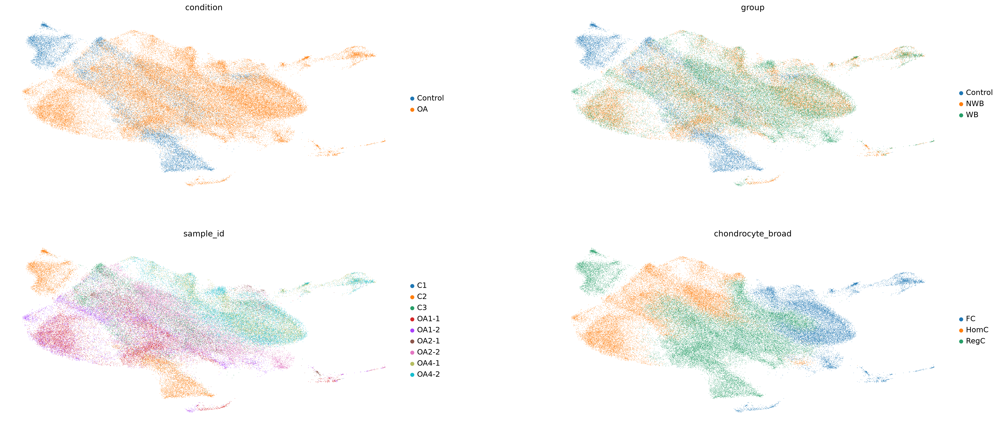

In [10]:
# ===== 2.2. Сравнение когорт: Osteoarthritis (OA) vs Control =====
print("Клетки по когортам (condition):")
print(adata.obs["condition"].value_counts())
print("\nКлетки по образцам (sample_id):")
print(adata.obs["sample_id"].value_counts())
print("\nКросс-таблица образец × когорта:")
display(pd.crosstab(adata.obs["sample_id"], adata.obs["condition"]))

sc.pl.umap(
    adata,
    color=["condition", "group", "sample_id", "chondrocyte_broad"],
    ncols=2,
    use_raw=False,
    wspace=0.25,
)


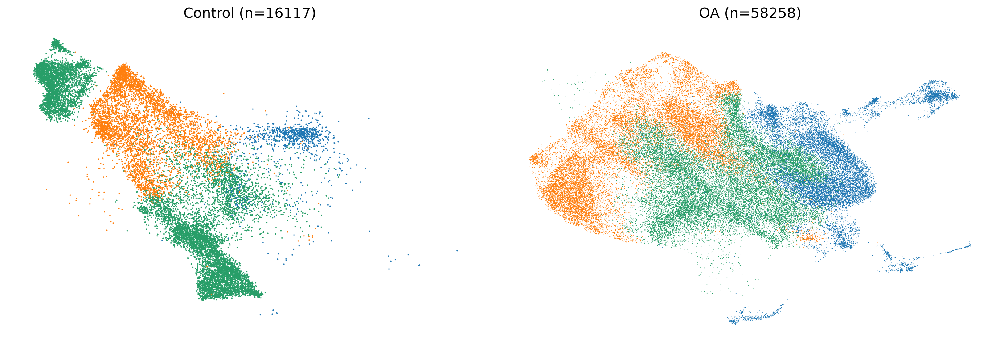

In [11]:
# Раздельный UMAP по когортам с одинаковыми цветами субпопуляций
conditions = list(adata.obs["condition"].cat.categories)
fig, axes = plt.subplots(1, len(conditions), figsize=(7 * len(conditions), 5), sharex=True, sharey=True)
if len(conditions) == 1:
    axes = [axes]

for ax, cond in zip(np.ravel(axes), conditions):
    n_cells = int((adata.obs["condition"] == cond).sum())
    sc.pl.umap(
        adata[adata.obs["condition"] == cond],
        color="chondrocyte_broad",
        ax=ax,
        show=False,
        legend_loc=None,
        title=f"{cond} (n={n_cells})",
    )

plt.tight_layout()
plt.show()


chondrocyte_broad,FC,HomC,RegC
condition,,,
Control,6.3%,29.2%,64.5%
OA,26.6%,31.6%,41.8%


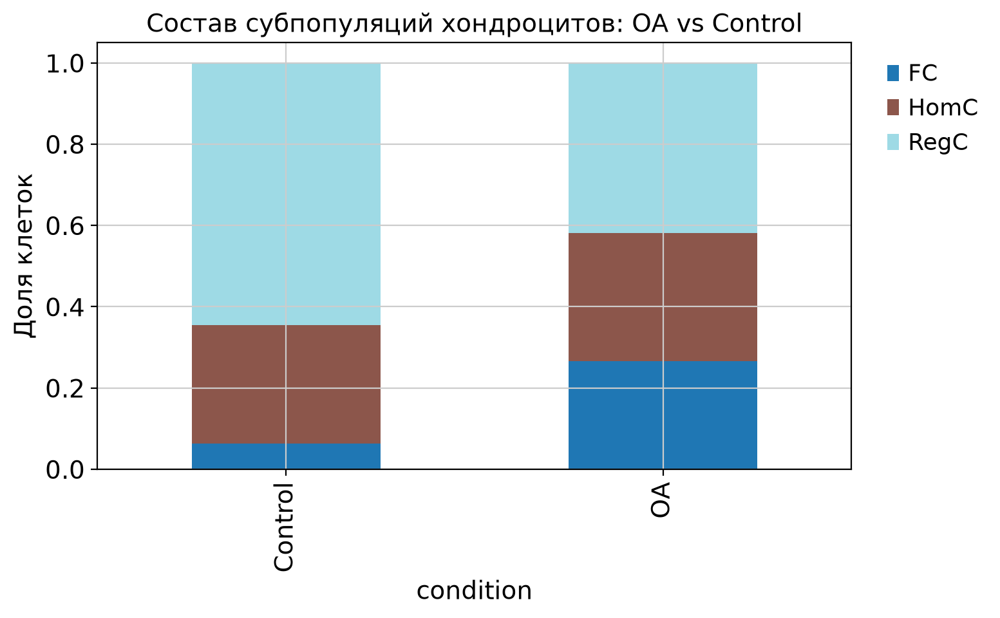

In [12]:
# Доли субпопуляций хондроцитов в когортах
prop = pd.crosstab(
    adata.obs["condition"], adata.obs["chondrocyte_broad"], normalize="index"
)
display(prop.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None))

prop.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="tab20")
plt.ylabel("Доля клеток")
plt.title("Состав субпопуляций хондроцитов: OA vs Control")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()


### Вывод: Остеоартрит сильно повышает количество фиброзных хондроцитов

### Итоговая таблица аннотаций

| Кластер (0.6) | Предполагаемый клеточный тип | Маркерные гены | Обоснование |
|---|---|---|---|
| 0, 2, 8 | HomC (Гомеостатические) | COL2A1, ACAN, COMP | Гены структурного матрикса здорового хряща |
| 1, 6 | RegC (Регуляторные) | CHI3L1, CRTAC1 | Гены ответа на стресс и ранней репарации |
| 4, 7 | FC (Фиброхондроциты) | COL1A2, COL3A1, PRG4 | Замещение гиалинового матрикса фиброзным (коллаген I/III) |
| 3, 9 | PreHTC (Прегипертрофические) | COL10A1, SPP1 | Маркеры эндохондрального окостенения и гипертрофии |
| 5, 10 | InfC (Воспалительные) | IL1B, MMP13, CXCL8 | Воспалительные цитокины и ферменты деградации |

---
## 3. Метаболический путь 15-PGDH (`HPGD`) и переключение сигналинга $PGE_2$


Проверим на реальных клетках хряща ключевые звенья каскада:
1. **Травма и провоспалительные цитокины:** `IL1B`, `TNF`, `IL6`, `NFKB1`.
2. **Синтез $PGE_2$ из арахидоновой кислоты:** фосфолипазы (`PLA2G2A`, `PLA2G4A`), циклооксигеназы (`PTGS2` / COX-2, `PTGS1` / COX-1) и простагландин Е-синтазы (`PTGES` / mPGES-1, `PTGES2`, `PTGES3`).
3. **Фермент деградации $PGE_2$ (твоя мишень):** 15-PGDH, ген **`HPGD`**.
4. **Рецепторный аппарат:** `PTGER4` (рецептор EP4), а также `PTGER1`, `PTGER2`, `PTGER3`.
5. **Анаболическая ветка (низкое воспаление, регенерация):** `PRKACA`, `PRKACB` (PKA) $
ightarrow$ `CREB1`, `ATF1` $
ightarrow$ **`SOX9`** $
ightarrow$ синтез матрикса (`COL2A1`, `ACAN`).
6. **Катаболическая ветка (гипервоспаление, деградация):** гиперактивация `PTGER4` $
ightarrow$ **`STAT3`** $
ightarrow$ транскрипция металлопротеиназ и аггреканаз (`MMP3`, `MMP13`, `ADAMTS4`, `ADAMTS5`).


In [37]:
pgdh_pathway_dict = {
    "1. 15-PGDH": ["HPGD"],
    "2. Синтез PGE2": ["PLA2G2A", "PLA2G4A", "PTGS1", "PTGS2", "PTGES", "PTGES2", "PTGES3"],
    "3. EP1-4": ["PTGER4", "PTGER2", "PTGER1", "PTGER3"],
    "4. Цитокины": ["IL1B", "TNF", "IL6", "NFKB1", "CXCL8"],
    "5. Анаболизм ": ["PRKACA", "PRKACB", "CREB1", "SOX9", "COL2A1", "ACAN"],
    "6. Катаболизм": ["STAT3", "MMP3", "MMP13", "ADAMTS4", "ADAMTS5"]
}

pgdh_pathway_present = {
    k: [g for g in v if g in adata.var_names]
    for k, v in pgdh_pathway_dict.items()
}
pgdh_pathway_present = {k: v for k, v in pgdh_pathway_present.items() if len(v) > 0}

print("Присутствующие в датасете гены исследуемого каскада:")
for k, v in pgdh_pathway_present.items():
    print(f"  {k}: {v}")


Присутствующие в датасете гены исследуемого каскада:
  1. 15-PGDH: ['HPGD']
  2. Синтез PGE2: ['PLA2G2A', 'PLA2G4A', 'PTGS1', 'PTGS2', 'PTGES', 'PTGES2', 'PTGES3']
  3. EP1-4: ['PTGER4', 'PTGER2', 'PTGER1', 'PTGER3']
  4. Цитокины: ['IL1B', 'TNF', 'IL6', 'NFKB1', 'CXCL8']
  5. Анаболизм : ['PRKACA', 'PRKACB', 'CREB1', 'SOX9', 'COL2A1', 'ACAN']
  6. Катаболизм: ['STAT3', 'MMP3', 'MMP13', 'ADAMTS4', 'ADAMTS5']


## Классно, все есть


### 3.1. Экспрессия 15-PGDH (`HPGD`) и всего каскада по субпопуляциям хондроцитов и группам (OA vs Control)


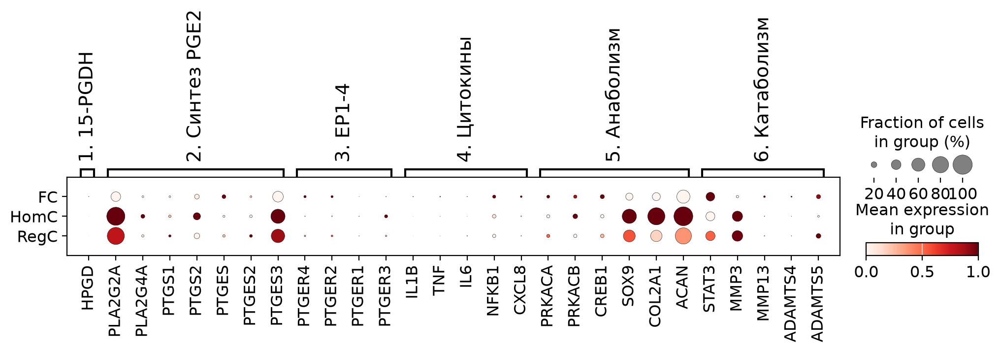

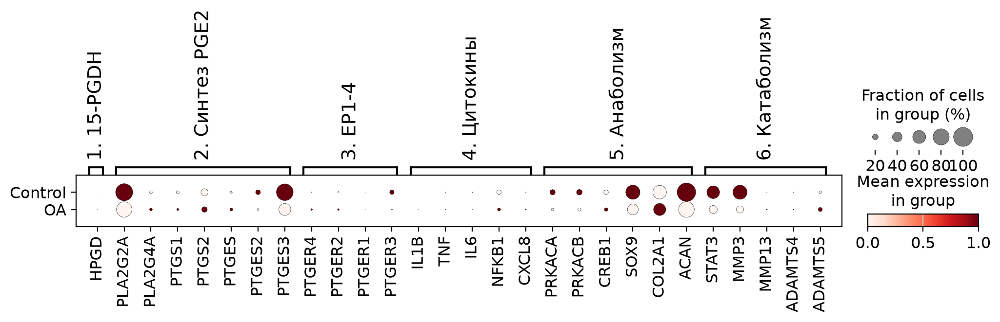

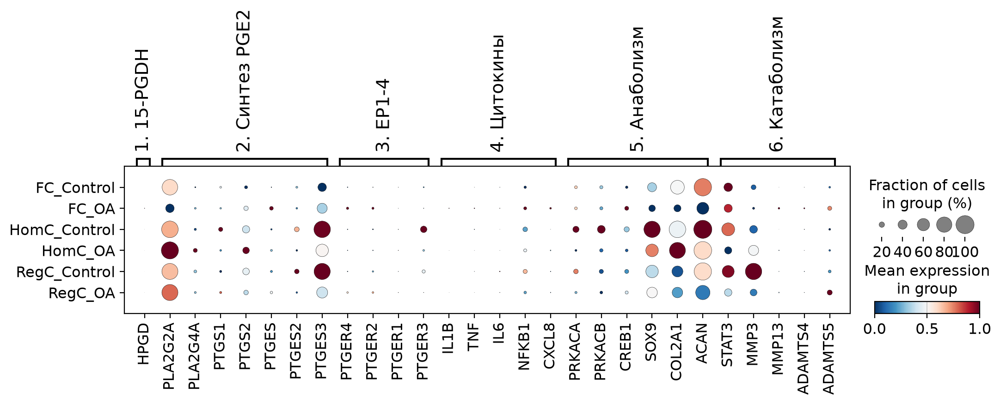

In [40]:
# DotPlot по функциональным популяциям хондроцитов
sc.pl.dotplot(
    adata,
    var_names=pgdh_pathway_present,
    groupby="chondrocyte_broad",
    use_raw=False,
    standard_scale="var",
)

# Если в condition больше 1 группы (например, Control vs OA), строим прямое сравнение
if adata.obs["condition"].nunique() > 1:
    sc.pl.dotplot(
        adata,
        var_names=pgdh_pathway_present,
        groupby="condition",
        use_raw=False,
        standard_scale="var",
    )

# --- Прямое сравнение когорт внутри каждого кластера ---
for cluster_key in ["chondrocyte_broad"]:
    sc.pl.dotplot(
        adata,
        var_names=pgdh_pathway_present,
        groupby=[cluster_key, "condition"],
        use_raw=False,
        standard_scale="var",
        cmap="RdBu_r",
    )



* `Inflammation_Score` — уровень цитокиновой стимуляции (`IL1B`, `TNF`, `IL6`, `NFKB1`, `CXCL8`).
* `PGE2_Synthesis_Score` — интенсивность наработки эндогенного $PGE_2$ (`PTGS2`, `PTGES`, `PLA2G2A`).
* `Anabolic_cAMP_SOX9_Score` — регенеративный ответ (`PRKACA`, `CREB1`, `SOX9`, `COL2A1`, `ACAN`).
* `Catabolic_STAT3_MMP_Score` — деструктивный ответ (`STAT3`, `MMP3`, `MMP13`, `ADAMTS4`, `ADAMTS5`).


### 3.2. Скоры и гены пути по кластерам с разбивкой OA vs Control

Сравниваем распределения скоров и экспрессии ключевых генов **внутри каждого кластера** с hue = `condition`. Это убирает эффект состава кластеров и показывает именно разницу между OA и контролем.


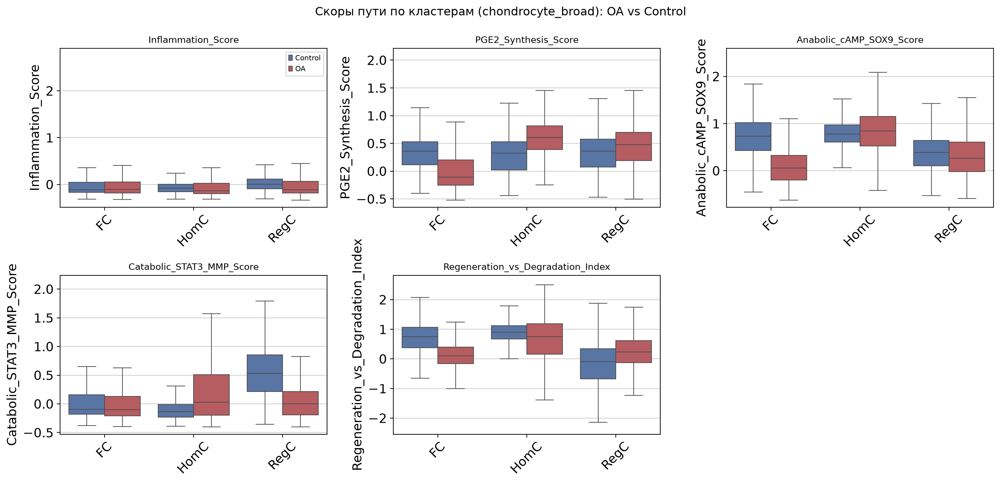

In [42]:
# Экспрессия всех генов пути в adata.obs (для индивидуальных сравнений)
pathway_genes = sorted({g for genes in pgdh_pathway_present.values() for g in genes})
for g in pathway_genes:
    col = f"expr_{g}"
    if col not in adata.obs.columns:
        vec = adata[:, g].X
        adata.obs[col] = vec.toarray().ravel() if sp.issparse(vec) else np.asarray(vec).ravel()

score_features = [
    "Inflammation_Score",
    "PGE2_Synthesis_Score",
    "Anabolic_cAMP_SOX9_Score",
    "Catabolic_STAT3_MMP_Score",
    "Regeneration_vs_Degradation_Index",
]
score_features = [f for f in score_features if f in adata.obs.columns]

key_genes = [
    "HPGD", "PTGER4", "PTGS2", "PTGES",
    "SOX9", "COL2A1", "ACAN",
    "STAT3", "MMP3", "MMP13", "ADAMTS4", "ADAMTS5",
]
gene_features = [f"expr_{g}" for g in key_genes if f"expr_{g}" in adata.obs.columns]
all_gene_cols = [f"expr_{g}" for g in pathway_genes if f"expr_{g}" in adata.obs.columns]


def grouped_boxplots(features, group_key, title, ncols=3):
    features = [f for f in features if f in adata.obs.columns]
    if not features:
        print(f"Нет данных для: {title}")
        return
    order = sorted(adata.obs[group_key].astype(str).unique())
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.8 * nrows), squeeze=False)
    axes = axes.ravel()
    palette = {"Control": "#4C72B0", "OA": "#C44E52"}
    for i, (ax, feat) in enumerate(zip(axes, features)):
        sns.boxplot(
            data=adata.obs,
            x=group_key,
            y=feat,
            hue="condition",
            order=order,
            palette=palette,
            ax=ax,
            fliersize=0,
            linewidth=0.8,
        )
        ax.set_title(feat, fontsize=10)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
        if ax.legend_ is not None:
            if i == 0:
                ax.legend(title="", fontsize=8, loc="upper right")
            else:
                ax.legend_.remove()
    for ax in axes[len(features):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


for group_key in ["chondrocyte_broad"]:
    grouped_boxplots(
        score_features, group_key,
        f"Скоры пути по кластерам ({group_key}): OA vs Control", ncols=3,
    )


### 3.3. Доказательство гипотезы «Терапевтического окна» для ингибиторов 15-PGDH (`HPGD`)

Разделим хондроциты на 3 режима воспалительного микроокружения по квантилям `Inflammation_Score`:
1. **Low Inflammation (Норма / Базальный уровень)** — низкий цитокиновый фон.
2. **Moderate Inflammation (Ранняя травма / Адаптивный ответ)** — умеренная активация.
3. **High Inflammation (Цитокиновый шторм / Деструктивный ОА)** — верхний квартиль воспаления, где запускается гиперэкспрессия `PTGER4` и сдвиг в `STAT3 -> MMP3/MMP13`.

Проверим, как меняется соотношение **Регенерация (`SOX9`) / Деградация (`STAT3/MMPs`)** и экспрессия **`HPGD`** в этих трёх состояниях.


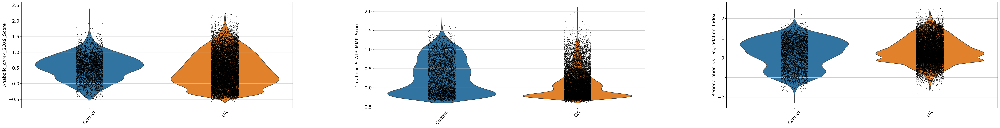

In [51]:

condition_violin_keys = [
    k for k in [
        "Anabolic_cAMP_SOX9_Score",
        "Catabolic_STAT3_MMP_Score",
        "Regeneration_vs_Degradation_Index",
    ]
    if k in adata.var_names or k in adata.obs.columns
]
# Те же ключевые показатели, но с прямой разбивкой OA vs Control

sc.pl.violin(
    adata,
    keys=condition_violin_keys,
    groupby="condition",
    rotation=50,
    use_raw=False,
)


### Вывод: Сильно меньше экспресиси анаболических генов при остеоартрите.

### Выводы: 1. При остеоартрите в FC клетках сильно снижается синтез PGE2 - бум, именно об этом говорили стенфордские чудилы. 2. Как следствие в FC клетках почти не работает анаболический путь при остеоартрите. при этом разницы в работе катаболического пути в FC клетках почти нет в зависимости от отсеоартрита - следовательно ингибирование 15-PGDH действительно активирует в FC анаболический путь

### 3.4. Анализ внутри `PTGER4+` (EP4-позитивных) хондроцитов: переключение с `CREB1/SOX9` на `STAT3/MMP13`
Отфильтруем клетки, экспрессирующие рецептор **EP4 (`PTGER4`)**, и построим график зависимости анаболического (`SOX9`) и катаболического (`STAT3/MMP13`) каскадов от уровня воспаления.


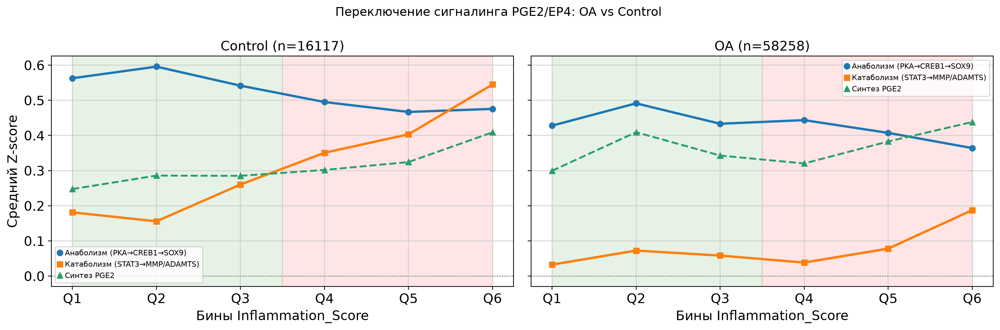

PTGER4+ клеток: 2429


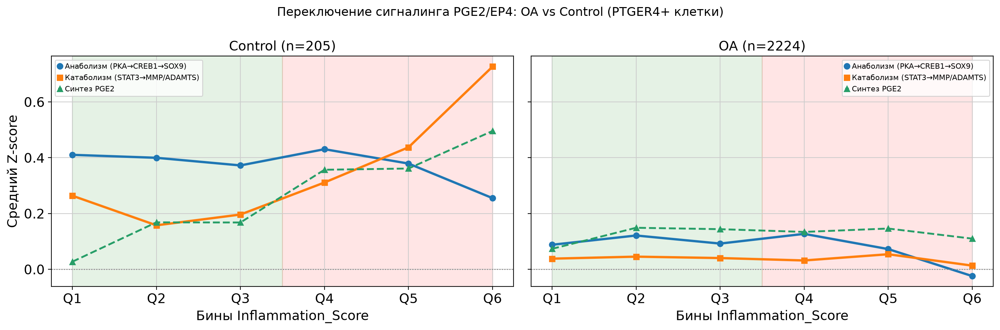

In [58]:
def plot_switch_by_condition(adata_obj, title_suffix="", n_bins=6):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for ax, cond in zip(axes, ["Control", "OA"]):
        sub = adata_obj.obs[adata_obj.obs["condition"].astype(str) == cond].copy()
        if sub.empty:
            ax.set_visible(False)
            continue
        sub["inf_bin"] = pd.qcut(
            sub["Inflammation_Score"].rank(method="first"),
            q=n_bins,
            labels=[f"Q{i}" for i in range(1, n_bins + 1)],
        )
        tr = sub.groupby("inf_bin", observed=False)[
            ["Anabolic_cAMP_SOX9_Score", "Catabolic_STAT3_MMP_Score", "PGE2_Synthesis_Score"]
        ].mean()
        ax.plot(tr.index, tr["Anabolic_cAMP_SOX9_Score"], marker="o", linewidth=2.5,
                label="Анаболизм (PKA→CREB1→SOX9)")
        ax.plot(tr.index, tr["Catabolic_STAT3_MMP_Score"], marker="s", linewidth=2.5,
                label="Катаболизм (STAT3→MMP/ADAMTS)")
        ax.plot(tr.index, tr["PGE2_Synthesis_Score"], marker="^", linestyle="--",
                linewidth=2, label="Синтез PGE2")
        ax.axhline(0, color="gray", linestyle=":", linewidth=1)
        ax.set_title(f"{cond} (n={len(sub)})")
        ax.set_xlabel("Бины Inflammation_Score")
        ax.legend(fontsize=8, loc="best")
        ax.axvspan(0, 2.5, color="green", alpha=0.10, label="Терапевтическое окно для ингибиторов 15-PGDH (низкое воспаление)")
        ax.axvspan(2.5, 5, color="red", alpha=0.10, label="Зона срыва в STAT3/MMP каскад (нужен15-PGDH / противовоспалительная терапия)")
    axes[0].set_ylabel("Средний Z-score")
    fig.suptitle(f"Переключение сигналинга PGE2/EP4: OA vs Control {title_suffix}", fontsize=13)
    fig.tight_layout()
    plt.show()




plot_switch_by_condition(adata)

if "expr_PTGER4" in adata.obs.columns:
    ptger4_pos = adata[adata.obs["expr_PTGER4"] > 0].copy()
    print(f"PTGER4+ клеток: {ptger4_pos.n_obs}")
    if ptger4_pos.n_obs > 0:
        plot_switch_by_condition(ptger4_pos, title_suffix="(PTGER4+ клетки)")


### Выводы: тут видно, что во первых - при остеоартрите чаще экспрессируется рецептор E4(не понятно почему) а во вторых, почему-то меньше общий уровень катаболической экспрессии(не понятно почему)

### Хорошее наблюдение, что на клетках контроля хорошо заметно что при высоком Inflammation_score катаболизм побеждает анаболизм, собственно как и в статьях. Но на OA этого не видно(

---
## 4. Пересчёт HVG по сырым каунтам (`layers['counts']`) и автоматическая аннотация CellTypist


HVG (seurat_v3, n_top=1000) успешно пересчитаны по .layers['counts'].


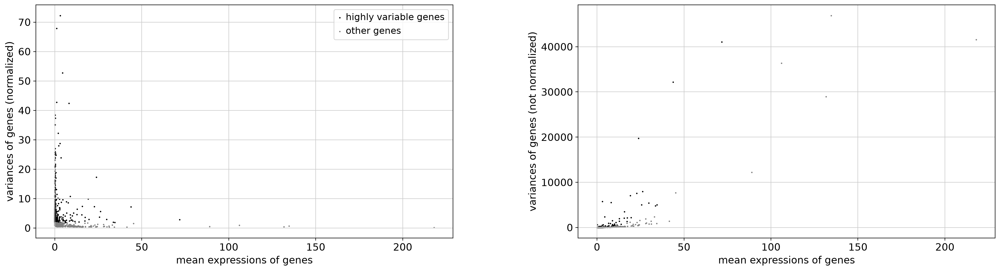

In [24]:
# Пересчёт топ-1000 высоковариабельных генов строго по сырым UMI-counts из .layers['counts']
try:
    sc.pp.highly_variable_genes(
        adata,
        layer="counts",
        flavor="seurat_v3",
        n_top_genes=1000,
        inplace=True
    )
    print("HVG (seurat_v3, n_top=1000) успешно пересчитаны по .layers['counts'].")
except Exception as e:
    print(f"seurat_v3 потребовал scikit-misc ({e}), используем flavor='seurat':")
    sc.pp.highly_variable_genes(adata, n_top_genes=1000, flavor="seurat", use_raw=False, inplace=True)

sc.pl.highly_variable_genes(adata)


### вместо шума из 34+ тысяч генов используются только 1000 генов с наибольшей биологической вариабельностью. Именно они несут ключевой сигнал, разделяющий хондроциты на функциональные кластеры.

In [62]:
# Задание 2: Топ-10 HVG
top_hvg = adata.var.sort_values(by="dispersions_norm", ascending=False).head(10)
print("Топ 10 высоковариабельных генов:")
print(top_hvg.index.tolist())

Топ 10 высоковариабельных генов:
['COL10A1', 'BGLAP', 'CCL4', 'MSMP', 'APOE', 'FABP4', 'IGFBP5', 'CCL3', 'SPARCL1', 'RGS5']


### 4.1. Запуск CellTypist


📂 Storing models in /home/khokholmongolll/.celltypist/data/models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)


🔬 Input data has 20000 cells and 34478 genes
🔗 Matching reference genes in the model
🧬 5998 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 15
🗳️ Majority voting the predictions
✅ Majority voting done!
... storing 'donor' as categorical


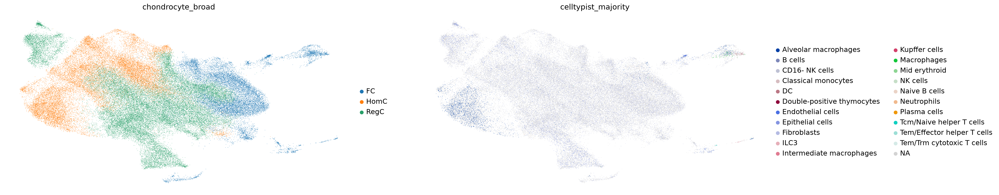

In [ ]:
RUN_CELLTYPIST = True  # True -> запустить CellTypist (на большом объекте берём подвыборку)

if not RUN_CELLTYPIST:
    print("CellTypist пропущен (RUN_CELLTYPIST=False). Включи, если нужен этот блок.")
else:
    try:
        import celltypist
        from celltypist import models

        models.download_models(force_update=False, model="Immune_All_Low.pkl")
        ct_model = models.Model.load(model="Immune_All_Low.pkl")

        rng = np.random.default_rng(42)
        idx = rng.choice(adata.n_obs, size=min(20000, adata.n_obs), replace=False)
        adata_ct = adata[idx].copy()
        adata_ct.X = adata_ct.layers["counts"].copyprint(f"Готово! Аннотированный датасет со всеми скорами сохранён в: {OUT_PATH}")()
        sc.pp.normalize_total(adata_ct, target_sum=1e4)
        sc.pp.log1p(adata_ct)

        predictions = celltypist.annotate(adata_ct, model=ct_model, majority_voting=True)
        pred_adata = predictions.to_adata()
        pred_series = pd.Series(
            pred_adata.obs["majority_voting"].values, index=adata.obs_names[idx]
        )
        adata.obs["celltypist_majority"] = pred_series.reindex(adata.obs_names).values

        sc.pl.umap(
            adata,
            color=["chondrocyte_broad", "celltypist_majority"],
            ncols=2,
            use_raw=False,
        )
    except ImportError:
        print("Пакет celltypist не установлен.")
    except Exception as exc:
        print(f"CellTypist пропущен: {exc}")


### Насрал тут конечно он

In [67]:
# Задание 5: Сравнение аннотаций
if "celltypist_majority" in adata.obs.columns:
    crosstab = pd.crosstab(adata.obs["chondrocyte_broad"], adata.obs["celltypist_majority"])
    display(crosstab)

celltypist_majority,Alveolar macrophages,B cells,CD16- NK cells,Classical monocytes,DC,Double-positive thymocytes,Endothelial cells,Epithelial cells,Fibroblasts,ILC3,...,Kupffer cells,Macrophages,Mid erythroid,NK cells,Naive B cells,Neutrophils,Plasma cells,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Trm cytotoxic T cells
chondrocyte_broad,,,,,,,,,,,,,,,,,,,,,
FC,260,1,2,51,75,1,160,50,3774,0,...,0,71,0,0,2,0,0,9,0,1
HomC,1511,8,0,2,1,1,0,256,4396,1,...,1,0,1,0,1,0,1,1,1,0
RegC,132,25,2,5,2,0,1,1672,7467,0,...,0,0,0,1,36,1,0,1,0,0


### Ну просто полная хрень

### Субкластеризация фиброхондроцитов!

Субкластеризация популяции FC (Фиброхондроциты)


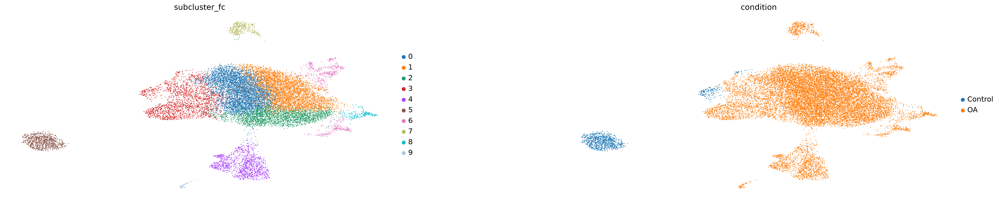

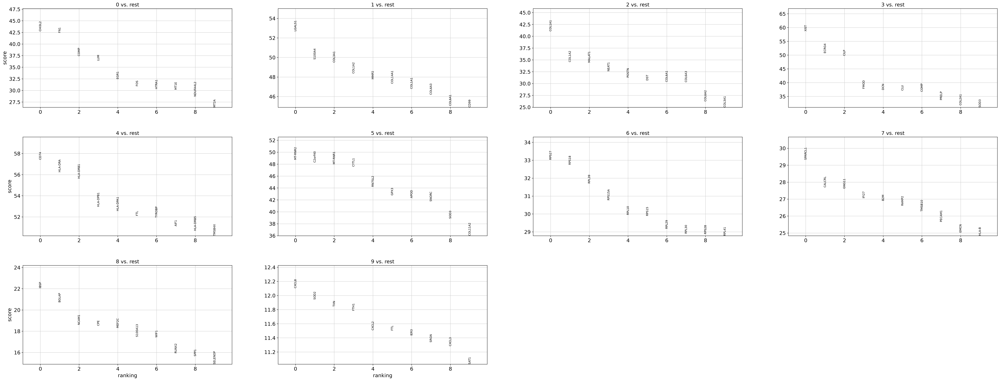

In [66]:
# Задание 6: Субкластеризация популяции FC
print("Субкластеризация популяции FC (Фиброхондроциты)")

# Надежный фильтр по вхождению "FC" в название аннотации
adata_fc = adata[adata.obs["chondrocyte_broad"].astype(str).str.contains("FC", na=False)].copy()

if adata_fc.n_obs > 0:
    # Повторяем препроцессинг для сабсета (БЕЗ use_raw)
    sc.pp.highly_variable_genes(adata_fc, n_top_genes=1000, flavor='seurat')
    sc.tl.pca(adata_fc, n_comps=30, random_state=42)
    sc.pp.neighbors(adata_fc, n_neighbors=10, random_state=42)
    sc.tl.umap(adata_fc, random_state=42)
    
    # Кластеризуем сабсет
    sc.tl.leiden(adata_fc, resolution=0.4, key_added='subcluster_fc', random_state=42)

    # Строим UMAP для субкластеров и групп пациентов
    sc.pl.umap(adata_fc, color=['subcluster_fc', 'condition'], wspace=0.3)

    # Ищем маркеры новых субкластеров
    sc.tl.rank_genes_groups(adata_fc, groupby='subcluster_fc', method='wilcoxon')
    sc.pl.rank_genes_groups(adata_fc, n_genes=10, sharey=False)
else:
    print("Клетки кластера FC не найдены. Проверьте название популяции.")

## 5. Сохранение финального аннотированного датасета


In [ ]:
OUT_PATH = DATA_DIR / "gse255460_annotated_15pgdh_diploma_multisample.h5ad"
adata.write_h5ad(OUT_PATH, compression="gzip")

# Финальный вывод



1. **Клеточные популяции:** Обнаружены основные состояния хондроцитов: гомеостатические (HomC), регуляторные (RegC), фиброхондроциты (FC)
2. **Маркерные гены:** COL2A1 (норма), COL1A2 (фиброз), SPP1 (гипертрофия), MMP13 (воспаление/деградация).
3. **Автоматическая аннотация:** Не согласуется с ручной, так как стандартные модели CellTypist  не подходят для специализированной ткани .
4. **Субкластеризация:** Позволила выявить внутреннюю гетерогенность в популяции фиброхондроцитов (FC).
5. **Генные программы:** Рассчитанные скоры воспаления, анаболизма и катаболизма подтвердили сдвиг фенотипа при остеоартрите и позволили протестировать гипотезу о бифазной роли сигналинга $PGE_2$/EP4. Показано, что при ОА анаболический путь подавлен, а катаболический активен, что делает ингибирование 15-PGDH перспективной стратегией.